Versión de TensorFlow: 2.21.0
Imágenes de entrenamiento: (60000, 28, 28)
Etiquetas de entrenamiento: (60000,)
Imágenes de prueba: (10000, 28, 28)
Etiquetas de prueba: (10000,)

Valor mínimo de un píxel: 0
Valor máximo de un píxel: 255


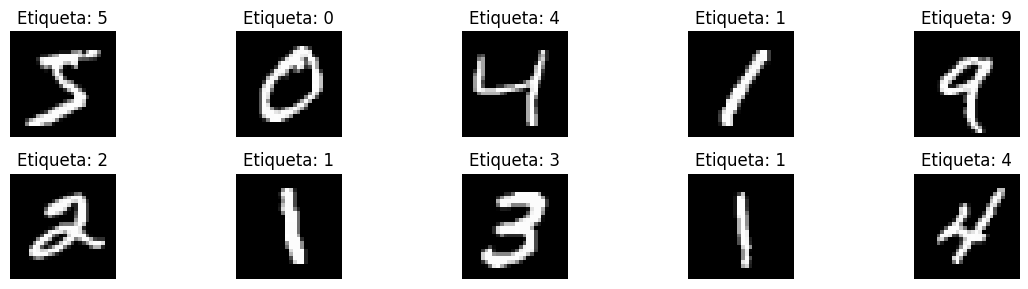

Nueva forma de x_train: (60000, 28, 28, 1)
Nueva forma de y_train: (60000, 10)
Valor máximo de un píxel ahora: 1.0
Etiqueta de la primera imagen en one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - accuracy: 0.8938 - loss: 0.3507 - val_accuracy: 0.9800 - val_loss: 0.0776
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.9660 - loss: 0.1092 - val_accuracy: 0.9850 - val_loss: 0.0576
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 99ms/step - accuracy: 0.9739 - loss: 0.0842 - val_accuracy: 0.9878 - val_loss: 0.0478
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9777 - loss: 0.0712 - val_accuracy: 0.9883 - val_loss: 0.0430
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9803 - loss: 0.0634 - val_accuracy: 0.9878 - val_loss: 0.0401


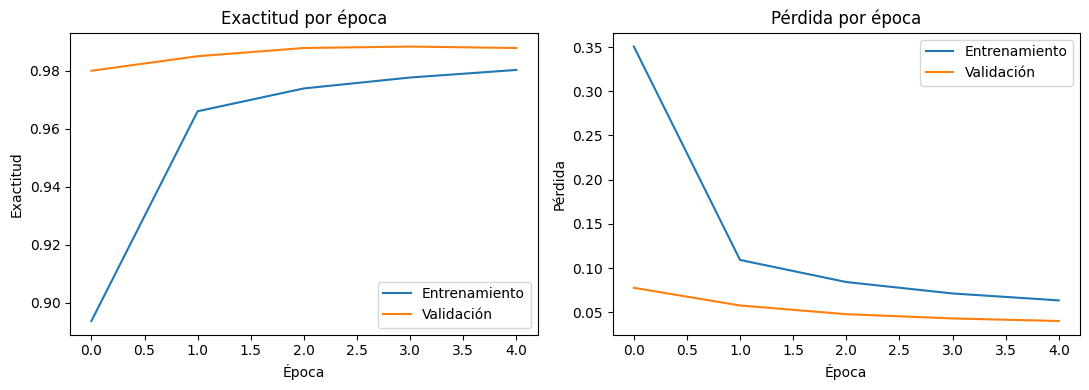

Pérdida en prueba: 0.0373
Exactitud en prueba: 98.75 %
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Probabilidades de la primera imagen de prueba:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]

Predicción: 7
Etiqueta real: 7


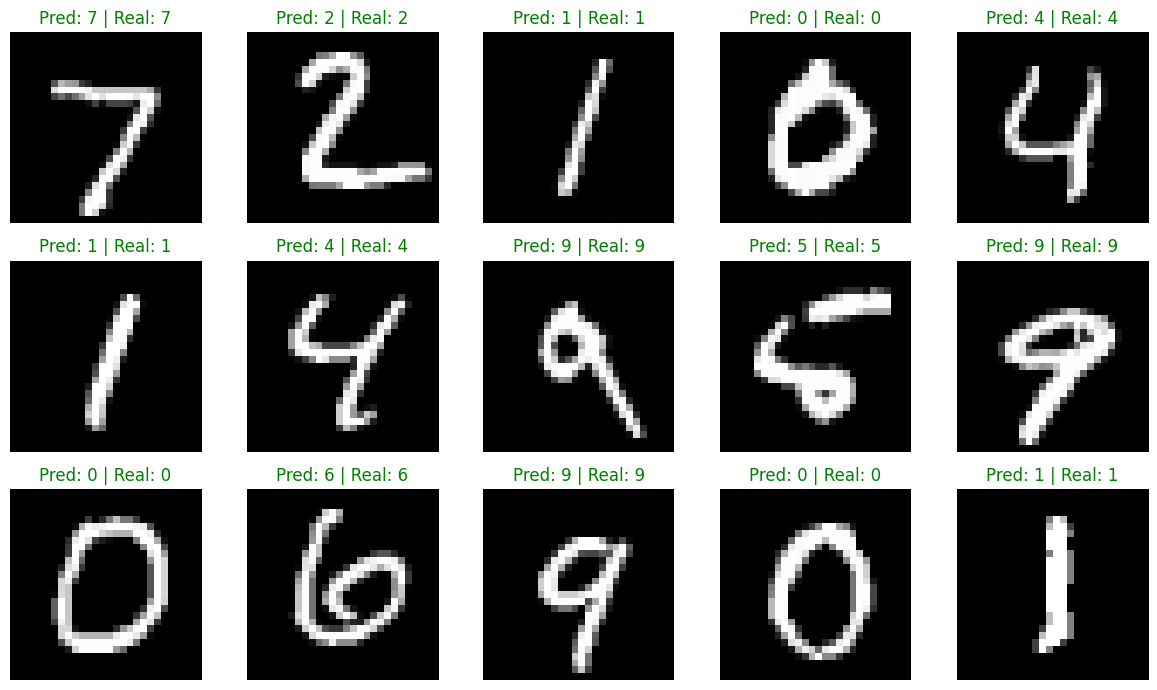

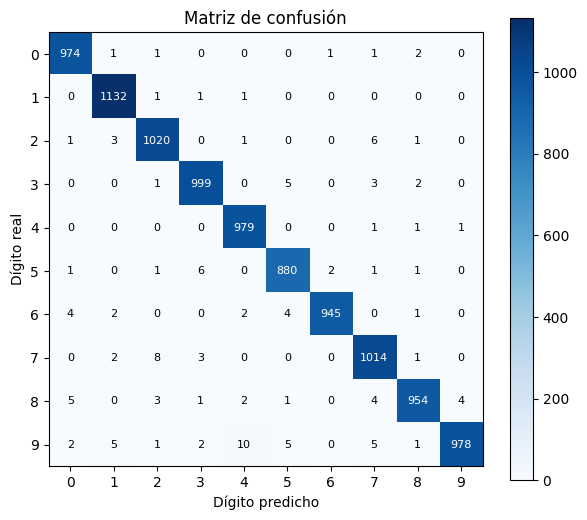

Total de errores: 125 de 10000 imágenes


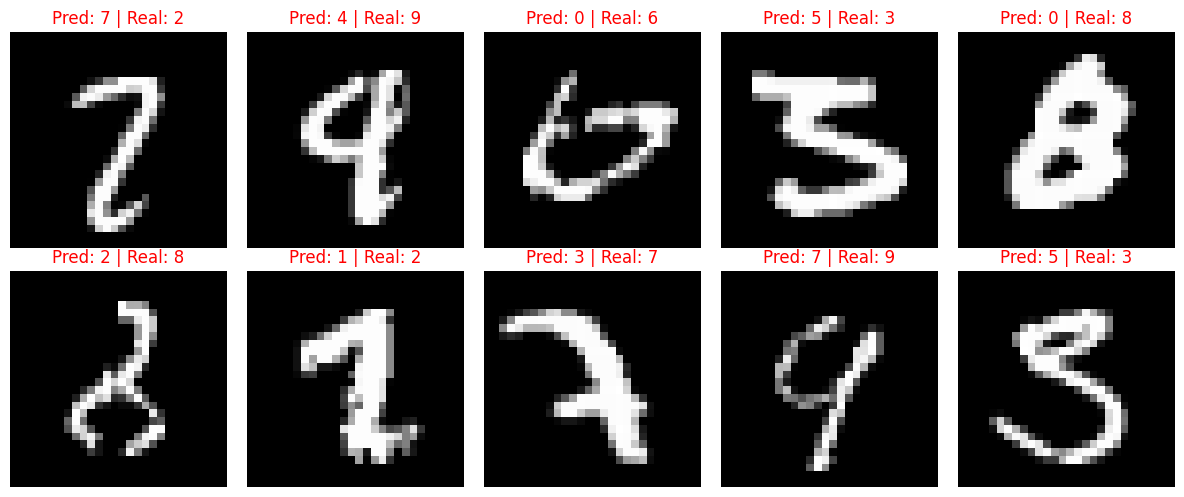

In [4]:
# # Práctica: Clasificación de dígitos escritos a mano con una CNN
#
# **Curso:** Redes Neuronales
# **Nombre:** _(Christian Alejandro Rojas Villegas)_
# **Fecha:** _(6 de noviembre del 2026)_
#
# ## Objetivo
# Entrenar una **red neuronal convolucional (CNN)** que reconozca dígitos del 0 al 9 escritos a mano, usando el conjunto de datos **MNIST**.
#
# ## Pasos que sigo en esta práctica
# 1. Importar las librerías.
# 2. Cargar el conjunto de datos MNIST.
# 3. Explorar y visualizar las imágenes.
# 4. Preparar las imágenes (normalizar, darles la forma correcta y transformar las etiquetas).
# 5. Construir la CNN.
# 6. Entrenar el modelo.
# 7. Evaluar el desempeño.
# 8. Hacer predicciones y mostrar ejemplos.
# 9. Interpretar los resultados.
#
# > **Nota:** esta práctica está pensada para ejecutarse en **Google Colab** (Entorno de ejecución → Ejecutar todo).

# ## 1. Importar las librerías
#
# Antes de empezar necesito las herramientas del proyecto:
# - **numpy**: para trabajar con arreglos de números (las imágenes son arreglos de números).
# - **matplotlib**: para dibujar las imágenes y las gráficas.
# - **tensorflow (tf)**: la librería con la que construyo y entreno la red neuronal. Usa su API de alto nivel `tf.keras`, que facilita armar las capas del modelo.

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

print("Versión de TensorFlow:", tf.__version__)

# ## 2. Cargar el conjunto de datos MNIST
#
# MNIST es una colección de **70,000 imágenes** de dígitos escritos a mano. Ya viene dividida en dos partes:
# - **Entrenamiento (60,000 imágenes):** con estas la red aprende.
# - **Prueba (10,000 imágenes):** son imágenes que la red nunca vio durante el entrenamiento; sirven para saber qué tan bien aprendió de verdad.
#
# Cada imagen tiene su **etiqueta**, que es el número que representa (0, 1, 2, ..., 9).
#
# La función `mnist.load_data()` descarga los datos y los regresa ya separados.

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# ## 3. Explorar los datos
#
# Reviso el tamaño de los arreglos para entender qué tengo. Cada imagen es de **28 x 28 píxeles** y cada píxel es un número entre **0** (negro) y **255** (blanco).

print("Imágenes de entrenamiento:", x_train.shape)
print("Etiquetas de entrenamiento:", y_train.shape)
print("Imágenes de prueba:", x_test.shape)
print("Etiquetas de prueba:", y_test.shape)
print()
print("Valor mínimo de un píxel:", x_train.min())
print("Valor máximo de un píxel:", x_train.max())

# Ahora dibujo las primeras 10 imágenes del conjunto de entrenamiento con su etiqueta real, para ver cómo se ven los dígitos.

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Etiqueta: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

# ## 4. Preparación de las imágenes
#
# Las imágenes no se pueden meter a la red tal como vienen. Hay que hacer tres cosas:
#
# **a) Normalizar.** Los píxeles van de 0 a 255. Si los divido entre 255 quedan entre 0 y 1. Esto ayuda a que la red entrene más rápido y con más estabilidad, porque trabaja mejor con números pequeños.
#
# **b) Agregar el canal.** Una CNN espera que cada imagen tenga la forma (alto, ancho, canales). Como las imágenes son en escala de grises tienen **1 canal** (una imagen a color tendría 3: rojo, verde y azul). Por eso paso de (28, 28) a (28, 28, 1).
#
# **c) Convertir las etiquetas a *one-hot*.** La etiqueta "3" se convierte en un vector de 10 posiciones con un 1 en la posición 3 y ceros en las demás: `[0,0,0,1,0,0,0,0,0,0]`. Así la red puede dar una salida por cada dígito.

# a) Normalizar: convertir a decimales y dividir entre 255
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

# b) Agregar la dimensión del canal
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Guardo las etiquetas originales (números) para usarlas después al comparar
y_test_numeros = y_test.copy()

# c) One-hot de las etiquetas
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print("Nueva forma de x_train:", x_train.shape)
print("Nueva forma de y_train:", y_train.shape)
print("Valor máximo de un píxel ahora:", x_train.max())
print("Etiqueta de la primera imagen en one-hot:", y_train[0])

# ## 5. Construcción de la CNN
#
# ### ¿Cómo funciona una CNN?
# Una red convolucional está pensada para trabajar con imágenes. En lugar de mirar todos los píxeles de golpe, va fijándose en **pedazos pequeños** de la imagen para detectar patrones (bordes, curvas, líneas) y luego combina esos patrones para reconocer el dígito completo.
#
# Las capas que uso son:
#
# - **Conv2D (convolución):** desliza un filtro pequeño (de 3x3) por toda la imagen y detecta patrones simples. Cada filtro aprende a buscar algo distinto. Uso la activación **ReLU**, que deja pasar los valores positivos y convierte los negativos en cero.
# - **MaxPooling2D:** reduce el tamaño de la imagen quedándose con el valor más grande de cada bloque de 2x2. Así la red se vuelve más rápida y se fija en lo más importante.
# - **Flatten:** "aplana" el resultado en una sola lista larga de números para poder pasarlo a las capas siguientes.
# - **Dropout:** apaga al azar una parte de las neuronas durante el entrenamiento (aquí 50%). Sirve para que la red no se memorice los datos (*sobreajuste*).
# - **Dense (capa final):** tiene 10 neuronas, una por dígito. Usa **softmax**, que convierte las salidas en probabilidades que suman 1. El dígito con mayor probabilidad es la predicción.

modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Primer bloque: detecta patrones simples
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Segundo bloque: detecta patrones más complejos
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Parte final: clasificación
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax"),
])

modelo.summary()

# El `summary()` muestra cada capa, la forma de su salida y cuántos **parámetros** tiene (los números que la red va ajustando al aprender). Se puede ver cómo la imagen se va haciendo más pequeña conforme pasa por las convoluciones y los pooling.

# ## 6. Compilar y entrenar el modelo
#
# Antes de entrenar hay que decirle a la red tres cosas (`compile`):
# - **Función de pérdida (`categorical_crossentropy`):** mide qué tan equivocada está la red. Es la adecuada cuando hay varias clases y las etiquetas están en one-hot.
# - **Optimizador (`adam`):** es el método que usa la red para ajustar sus parámetros y reducir el error.
# - **Métrica (`accuracy`):** el porcentaje de aciertos, que es fácil de interpretar.
#
# Después se entrena con `fit`:
# - **epochs = 5:** la red ve el conjunto de entrenamiento completo 5 veces.
# - **batch_size = 128:** actualiza sus parámetros cada 128 imágenes.
# - **validation_split = 0.1:** aparta el 10% de las imágenes de entrenamiento para ir revisando, después de cada época, cómo le va con datos que no usó para aprender.

modelo.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

historial = modelo.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
)

# ## 7. Evaluación del desempeño
#
# ### 7.1 Curvas de aprendizaje
# Grafico la exactitud (accuracy) y la pérdida (loss) en cada época, tanto para los datos de entrenamiento como para los de validación. Me sirve para ver si la red está aprendiendo y si hay sobreajuste (cuando entrenamiento mejora mucho pero validación no).

plt.figure(figsize=(11, 4))

# Gráfica de exactitud
plt.subplot(1, 2, 1)
plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validación")
plt.title("Exactitud por época")
plt.xlabel("Época")
plt.ylabel("Exactitud")
plt.legend()

# Gráfica de pérdida
plt.subplot(1, 2, 2)
plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validación")
plt.title("Pérdida por época")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()

plt.tight_layout()
plt.show()

# ### 7.2 Evaluación con el conjunto de prueba
# Ahora sí uso las 10,000 imágenes de prueba, que la red nunca vio. Este resultado es el que realmente dice qué tan bien generaliza el modelo.

perdida, exactitud = modelo.evaluate(x_test, y_test, verbose=0)

print("Pérdida en prueba:", round(perdida, 4))
print("Exactitud en prueba:", round(exactitud * 100, 2), "%")

# ## 8. Predicciones
#
# Con `modelo.predict` la red devuelve, para cada imagen, **10 probabilidades** (una por dígito). Con `np.argmax` me quedo con la posición de la probabilidad más alta, que es el dígito que la red predice.

probabilidades = modelo.predict(x_test)
predicciones = np.argmax(probabilidades, axis=1)

print("Probabilidades de la primera imagen de prueba:")
print(np.round(probabilidades[0], 3))
print()
print("Predicción:", predicciones[0])
print("Etiqueta real:", y_test_numeros[0])

# ### 8.1 Ejemplos de dígitos con su predicción
# Muestro 15 imágenes de prueba. Arriba de cada una aparece la predicción de la red (`Pred`) y el valor real (`Real`). Si acertó el título sale en **verde** y si falló en **rojo**.

plt.figure(figsize=(12, 7))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")

    if predicciones[i] == y_test_numeros[i]:
        color = "green"
    else:
        color = "red"

    plt.title("Pred: " + str(predicciones[i]) + " | Real: " + str(y_test_numeros[i]), color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

# ### 8.2 Matriz de confusión
# La calculo con `tf.math.confusion_matrix`. Es una tabla que compara lo real con lo predicho. Las **filas** son el dígito real y las **columnas** el dígito que predijo la red. Lo ideal es que los números grandes estén en la diagonal (aciertos). Los números fuera de la diagonal son errores, y me dicen qué dígitos se confunde la red entre sí.

matriz = tf.math.confusion_matrix(y_test_numeros, predicciones).numpy()

plt.figure(figsize=(7, 6))
plt.imshow(matriz, cmap="Blues")
plt.colorbar()
plt.title("Matriz de confusión")
plt.xlabel("Dígito predicho")
plt.ylabel("Dígito real")
plt.xticks(range(10))
plt.yticks(range(10))

# Escribir el número dentro de cada celda
for fila in range(10):
    for columna in range(10):
        if matriz[fila, columna] > matriz.max() / 2:
            color_texto = "white"
        else:
            color_texto = "black"
        plt.text(columna, fila, matriz[fila, columna], ha="center", va="center", color=color_texto, fontsize=8)

plt.show()

# ### 8.3 Ejemplos donde la red se equivocó
# Busco las imágenes mal clasificadas y muestro algunas. Esto ayuda a entender qué tipo de errores comete.

# %%
# Posiciones de las imágenes donde la predicción no coincide con la etiqueta real
errores = np.where(predicciones != y_test_numeros)[0]
print("Total de errores:", len(errores), "de", len(y_test_numeros), "imágenes")

plt.figure(figsize=(12, 5))
for j in range(10):
    i = errores[j]
    plt.subplot(2, 5, j + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Pred: " + str(predicciones[i]) + " | Real: " + str(y_test_numeros[i]), color="red")
    plt.axis("off")
plt.tight_layout()
plt.show()

# ## 9. Interpretación de los resultados
#
# **Exactitud.** Con esta arquitectura y 5 épocas, MNIST normalmente da una exactitud en prueba de alrededor del **98% al 99%**. Eso significa que de cada 100 dígitos que la red nunca había visto, acierta casi todos. Mi resultado fue: _(98.00, 0.0000)_.
#
# **Curvas de aprendizaje.** En las gráficas se espera ver que la exactitud sube y la pérdida baja en las primeras épocas. Si las curvas de entrenamiento y validación van parecidas y cercanas, quiere decir que la red **no se está sobreajustando**. En mi caso observé: _(las lineas quedaron muy parecidas asi que la red no se sobreajustando )_.
#
# **Matriz de confusión y errores.** La diagonal tiene los números más grandes, así que la mayoría de las predicciones son correctas. Los errores que comete suelen ser entre dígitos que se parecen, o con dígitos mal escritos que incluso a una persona le costaría reconocer (por ejemplo 4 y 9, o 3 y 5). Los errores más frecuentes en mi matriz fueron: _(7 y 9,5 y 3,4 y 9)_.
#
# **Conclusión.** La CNN logra clasificar dígitos escritos a mano con muy buena precisión porque aprende por sí sola a detectar patrones visuales en las imágenes, sin que yo tenga que decirle cómo es cada número. Algunas cosas que se podrían probar para mejorar: entrenar más épocas, agregar otra capa convolucional o cambiar el porcentaje de Dropout.
